In [76]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
gdrive_dir = '/content/drive/'


pd.set_option('display.max_rows',None)
warnings.filterwarnings('ignore')

In [77]:
File = "./.data/hu_intraday_vwap_15min_2023_2025.csv"
df=pd.read_csv(File)

In [79]:
df['target']=df['QH WAP']
df['timestamp']=pd.to_datetime(df['timestamp'])
df.drop(columns=['QH WAP'],inplace=True)
df=df.sort_values('timestamp').copy()

In [80]:
df['timestamp'].duplicated().any()

np.False_

In [81]:
df.duplicated().any()

np.False_

В датасете пропусков строк (по датам) нет, дубликатов в целом и по датам в частности тоже нет

In [82]:
df.isna().sum()

timestamp                     0
demand_forecast_mwh           0
wind_forecast_mwh             0
solar_forecast_mwh            0
nuclear_forecast_mwh          0
temperature_forecast_c        0
net_exchange_forecast_mwh     0
target                       94
dtype: int64

In [83]:
df['slot']=df['timestamp'].dt.hour*4+df['timestamp'].dt.minute//15

median_7d=(df.groupby('slot')['target'].transform(lambda x: x.shift(1).rolling(7, min_periods=1).median()))
df['target']=df['target'].fillna(median_7d)
df.drop(columns=['slot'],inplace=True)

Пропуски были в таргете, заполнены медианой последних 14 дней таких же 15 минуток. Такое решение было принято вместо удаления, для сохранения непрерывной временной структуры и для более удобного и четкого построения лаговых признаков.

Общее распределение

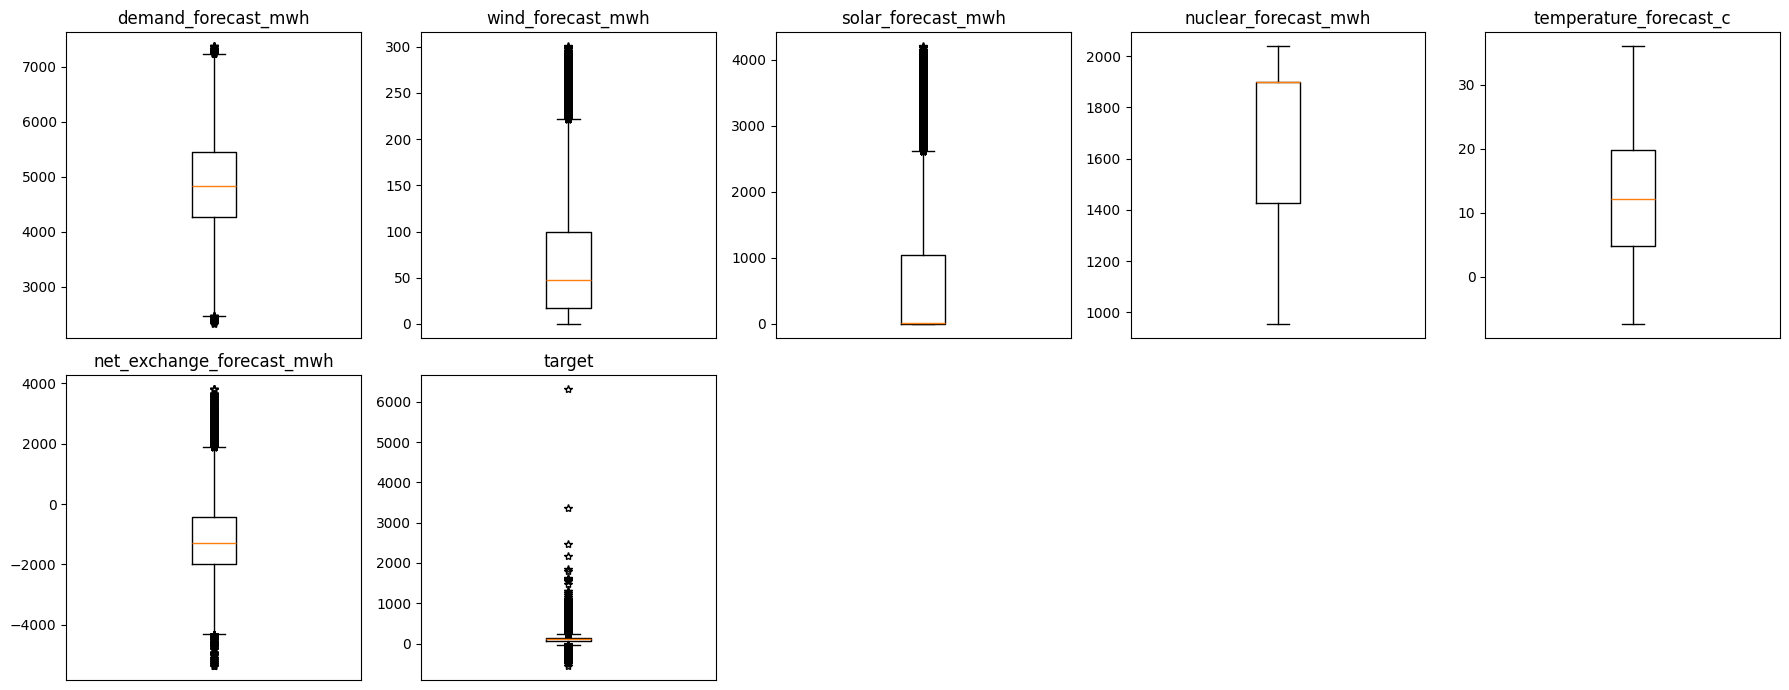

In [84]:
X = df.drop(columns='target')
y = df['target']

data = pd.concat([X, y], axis=1)
num_cols = data.select_dtypes(include="number").columns

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, num_cols):
    values = data[col].dropna().to_numpy(dtype=float)
    ax.boxplot(values, sym="*")
    ax.set_title(col)
    ax.set_xticks([])

for ax in axes.flat[len(num_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

В общем и целом выбросов кромое  QH WAP нету. В QH WAP нужно обрезать данные, а у остальных оставить как есть. Можно еще обрезать, конечно, у solar_forecast_mwh, тк данные выходят далека за усики. Кстати, исходя из графика solar_forecast_mwh, можно сказать, что min = 0 и медиана 0, что логично(значит данные распределены в основном у цифры 0 и ниже быть не может). Можно так же сказать, что у nuclear_forecst_mwh медиана находится очень, высоко, что говорит нам о том, что в основном цифры будут большие. Кстати QH WAP, когда ниже 0 это значит, что компания уходит в минус. 

Распределение положительных цен

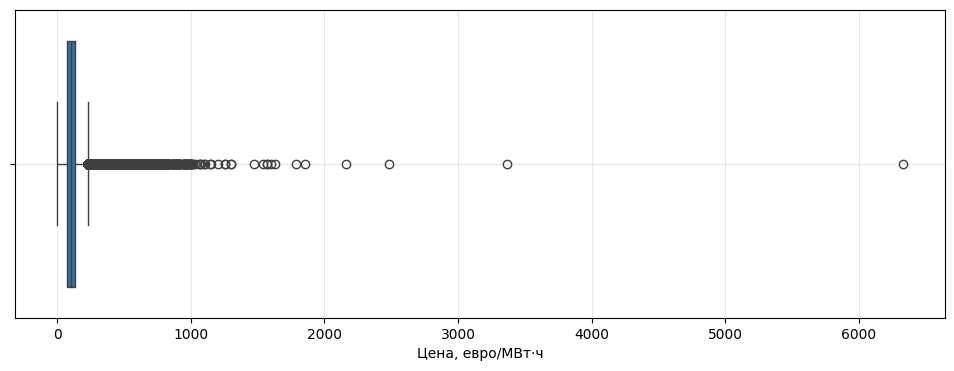

In [85]:
pos_target=df[df['target']>=0].reset_index(drop=True)
plt.figure(figsize=(12, 4))
sns.boxplot(x=pos_target['target'])
plt.xlabel('Цена, евро/МВт·ч')
plt.grid(alpha=0.3)
plt.show()

Распределение отрицательных цен

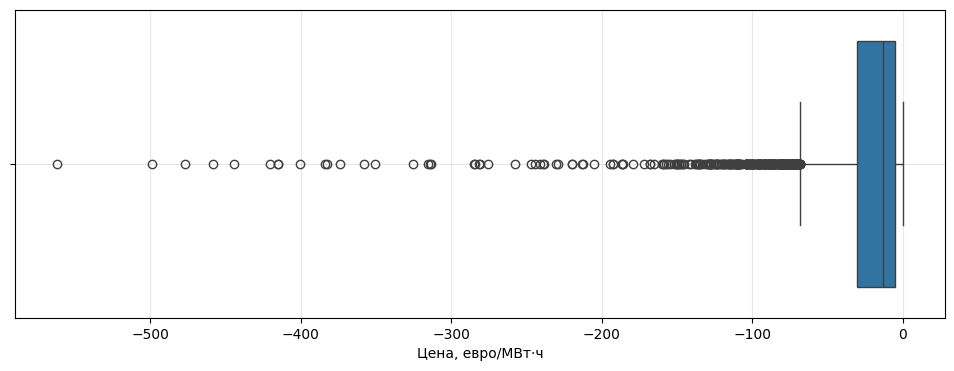

In [86]:
neg_target=df[df['target']<0].reset_index(drop=True)
plt.figure(figsize=(12, 4))
sns.boxplot(x=neg_target['target'])
plt.xlabel('Цена, евро/МВт·ч')
plt.grid(alpha=0.3)
plt.show()

In [87]:
neg_q05=neg_target['target'].quantile(0.05)
print("5 квантиль отрицательных значений",np.round(neg_q05,2))
pos_q95=pos_target['target'].quantile(0.95)
print("95 квантиль положительных значений",np.round(pos_q95,2))
q01=df['target'].quantile(0.01)
q05=df['target'].quantile(0.05)
q95=df['target'].quantile(0.95)
q99=df['target'].quantile(0.99)
print("1 квантиль:", np.round(q01,2))
print("5 квантиль:", np.round(q05,2))
print("95 квантиль:", np.round(q95,2))
print("99 квантиль:", np.round(q99,2))

5 квантиль отрицательных значений -85.54
95 квантиль положительных значений 224.5
1 квантиль: -29.51
5 квантиль: 5.37
95 квантиль: 222.13
99 квантиль: 377.66


In [88]:
df['target']=df['target'].clip(neg_q05,pos_q95)

В качестве обрезки выбросов принято решение разделить датасет на сэмплы с положительным и отрицательным таргетом, взять соотвественно нижний 5% квантиль у отрицательных и 95% у положительных. Поскольку присутсвует "хвост" в сторону больших значений и в случае выбора обрезки по 5-95 квантилям сэмплы с отрицательными значениями пропадают, что отнимает у модели часть предметной области. А обрезка по 1-99 квантилям оставляет достаточно выбросов с большими значениями и также существенно затрагивает сэмплы с отрицательными значениями

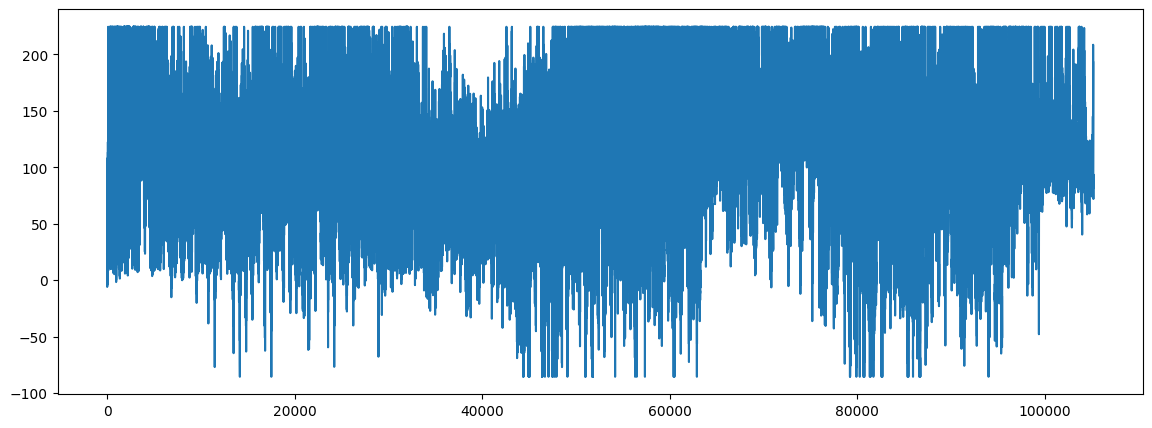

In [89]:
plt.figure(figsize=(14,5))
plt.plot(df['target'])
plt.show()

Для лучшей визуализации ряда построим графики с помощью медианного фильтра и скользящего среднего

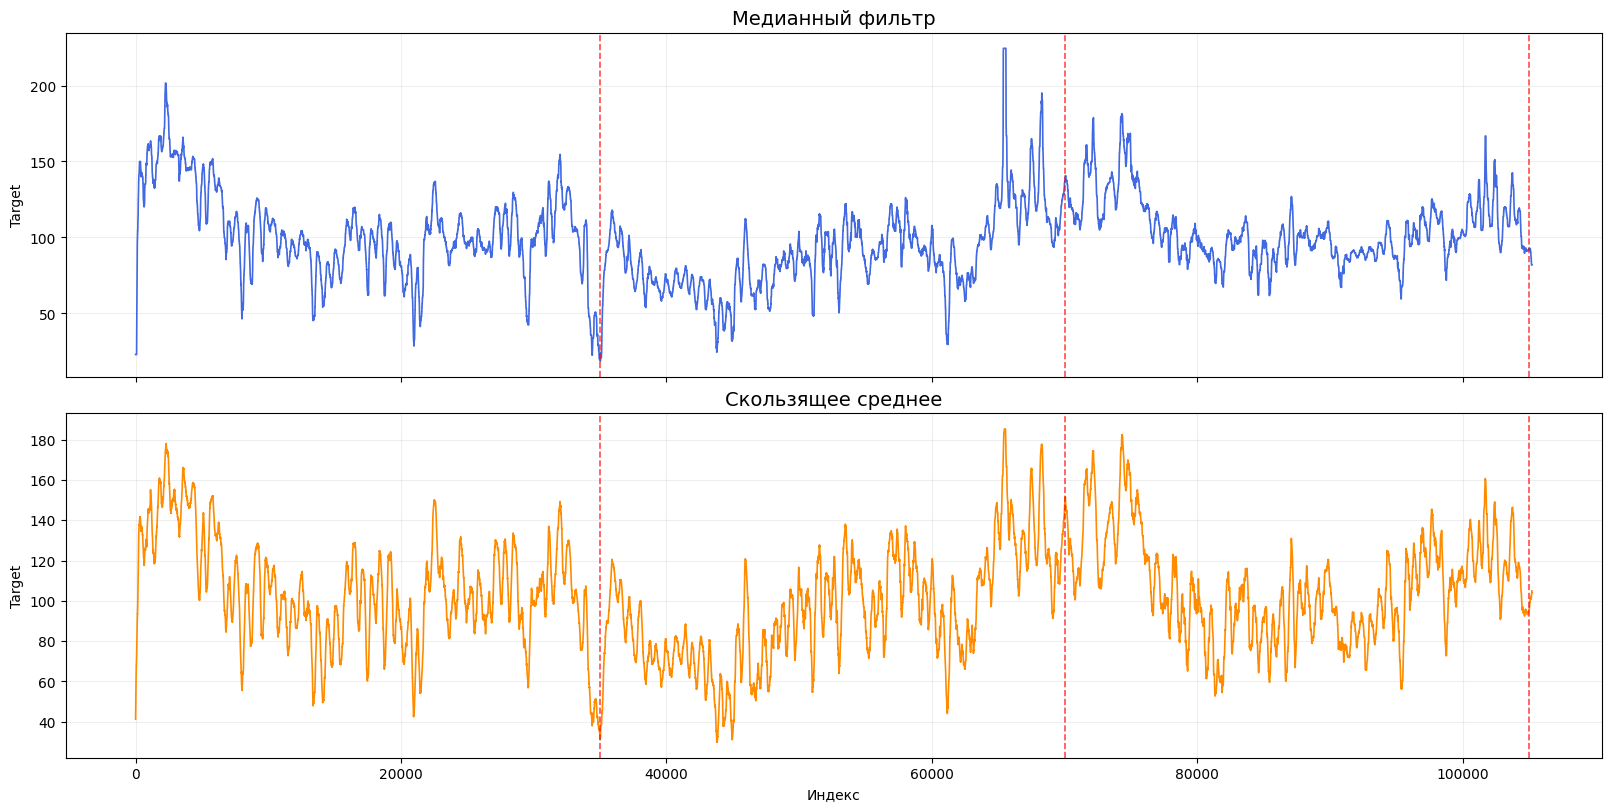

In [90]:
from scipy.ndimage import median_filter

y = df['target']
window = 288 #сглаживание по 3 дням

y_median = median_filter(y.to_numpy(), size=window, mode='nearest')
y_mean = y.rolling(window=window, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)

axes[0].plot(y.index, y_median, color='royalblue', linewidth=1.2)
axes[0].set_title('Медианный фильтр', fontsize=14)
axes[0].set_ylabel('Target')
axes[0].grid(alpha=0.2)

axes[1].plot(y.index, y_mean, color='darkorange', linewidth=1.2)
axes[1].set_title('Скользящее среднее', fontsize=14)
axes[1].set_xlabel('Индекс')
axes[1].set_ylabel('Target')
axes[1].grid(alpha=0.2)

for ax in axes:
    for i in range(35000, len(y), 35000):
        ax.axvline(y.index[i], color='red', linestyle='--', linewidth=1.2, alpha=0.7)
plt.show()

Проверим сезонность, построим автокорреляцию

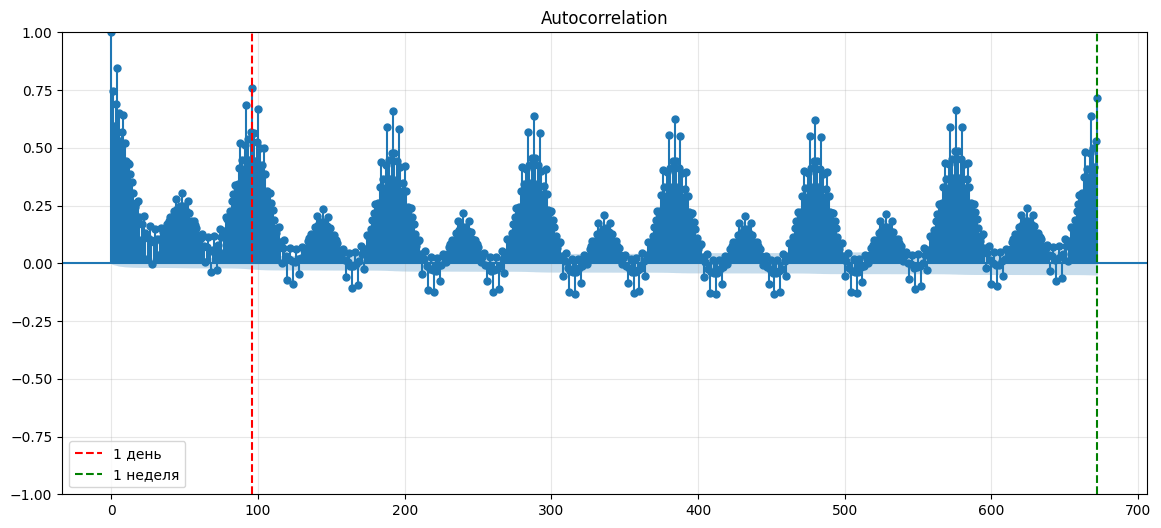

In [91]:
from statsmodels.graphics.tsaplots import plot_acf

y=df['target']
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=672,fft=True,alpha=0.05,ax=ax)
ax.axvline(96,color='red',ls='--',label='1 день')
ax.axvline(672,color='green',ls='--',label='1 неделя')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Из acf видно, что присутствует ежедневная, 12 и немного 6 часовая сезонность. Также стоит проверить на большем интервале времени месячную и недельную сезонность

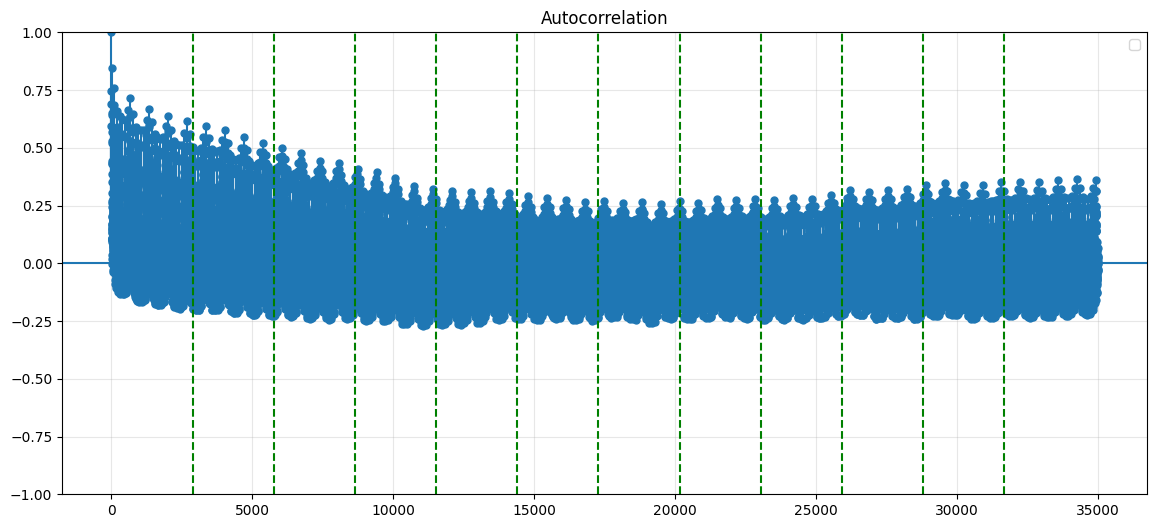

In [92]:
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=35000,fft=True,alpha=0.05,ax=ax)
for i in range(1,12):
  ax.axvline(2880*i,color='green',ls='--')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Из автокорреляции видно, что выраженной месячной сезонности не наблюдается, а вот внутри зеленых линий (месяцов) заметна уже недельная сезонность

Таким образом, из acf можно сделать вывод, что у ряда наблюдается недельная (672 точки), суточная (96 точек), 12-часовая (48 точек) и 6-часовая (24 точки) сезонности

Для определения близких лагов таргета построим коррелограмму на ближайшие 3 дня

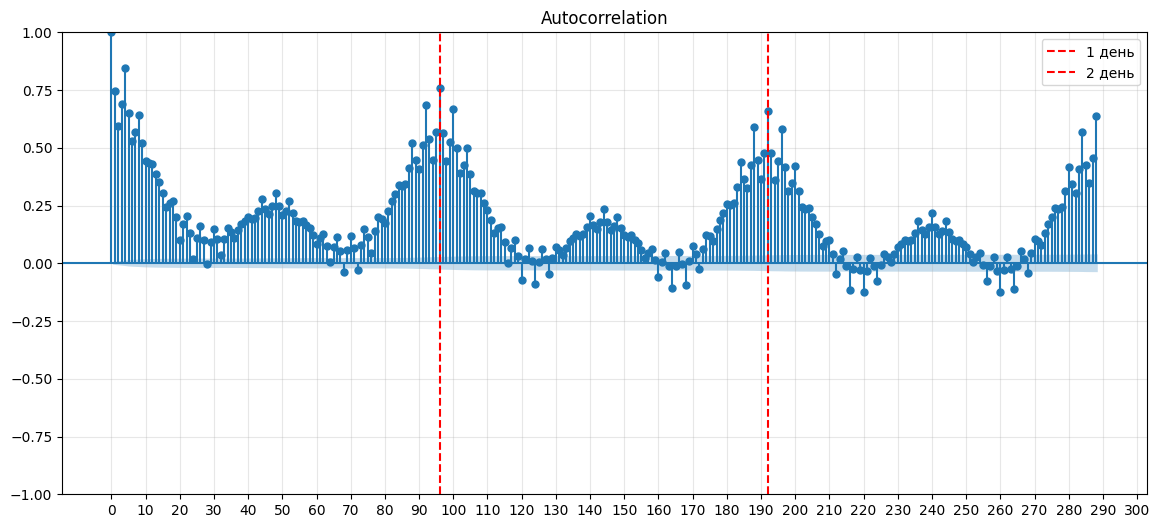

In [93]:
fig,ax=plt.subplots(figsize=(14,6))
plot_acf(y,lags=288,fft=True,alpha=0.05,ax=ax)
ax.axvline(96,color='red',ls='--',label='1 день')
ax.axvline(192,color='red',ls='--',label='2 день')
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(np.arange(0, 301, 10))
plt.show()

В качестве лагов ближайших дней были взяты 1-9, 48, 88-104, 124, 144, 164, 184-200, 220, 240, 260, 280-296, 672 (недельная сезонность). Скользящие средние с окном 24, 48, 96, 192 начиная с предыдущих суток

In [94]:
lags = [*range(1, 10), 48, *range(88,105), 124, 144, 164, *range(184, 201), 220, 240, 260, *range(280, 297), 672]
windows = [24, 48, 96, 192]

position=df['timestamp'].dt.hour*4+df['timestamp'].dt.minute//15+1

for lag in lags:
    df[f'lag_{lag}'] = df['target'].shift(lag)
    if lag < 96:
        df[f'lag_{lag}'] = df[f'lag_{lag}'].mask(position > lag)

for window in windows:
    df[f'rolling_mean_{window}'] = df['target'].shift(96).rolling(window).mean()

Удалим первые 672 строки, чтобы убрать сэмплы с большим количеством пропусков из-за построения лагов

In [95]:
df=df.iloc[672:].reset_index(drop=True)

Добавим календарные признаки по венгерскому времени: месяц, день недели, час, номер 15-минутки внутри дня, флаг праздника/выходного страны Венгрия

In [96]:
import holidays

ts=df["timestamp"].dt.tz_convert("Europe/Budapest")

df['year'] = df['timestamp'].dt.year
df['month']=ts.dt.month
df['week_of_year'] = df['timestamp'].dt.isocalendar().week
df['day_of_week']=ts.dt.dayofweek
df['day_of_month']=ts.dt.day
df['hour']=ts.dt.hour
df['quarter_hour']=ts.dt.hour*4+ts.dt.minute//15

hu_holidays=holidays.country_holidays('HU',years=ts.dt.year.unique().tolist())
df['is_weekend_holiday']=((ts.dt.dayofweek>=5)|ts.dt.date.isin(hu_holidays)).astype('int')

Проверим распределение значений признаков

Признак demand_forecast_mwh


,Значение,"Доля, %"
0,4456.1,0.01
1,5023.7,0.01
2,4998.3,0.01
3,4845.9,0.01
4,4687.6,0.01


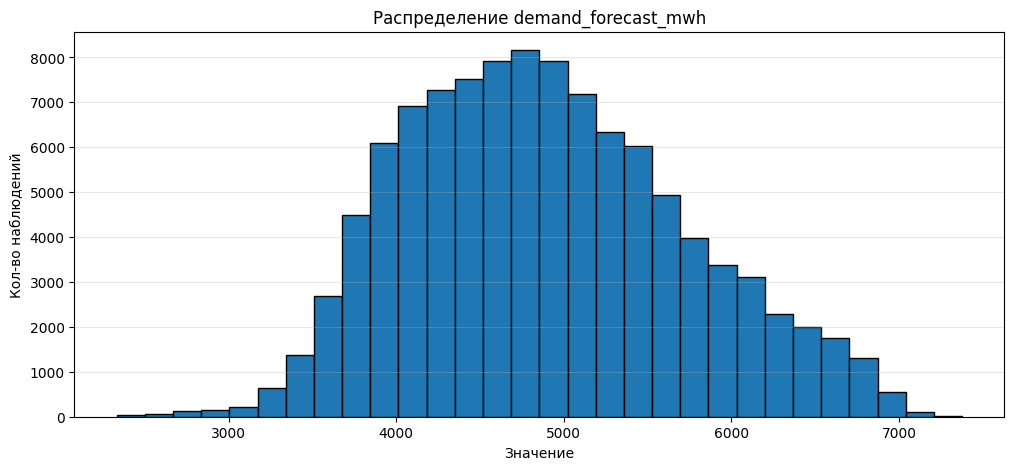

Признак wind_forecast_mwh


,Значение,"Доля, %"
0,6.7,0.26
1,5.7,0.26
2,6.6,0.25
3,5.0,0.25
4,7.0,0.25


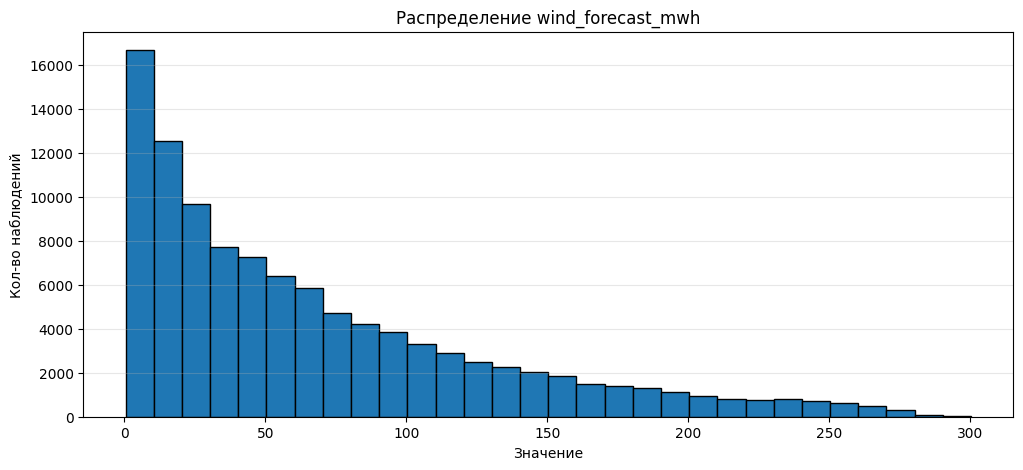

Признак solar_forecast_mwh


,Значение,"Доля, %"
0,0.0,47.52
1,0.1,0.15
2,0.2,0.10
3,0.3,0.07
4,0.6,0.06


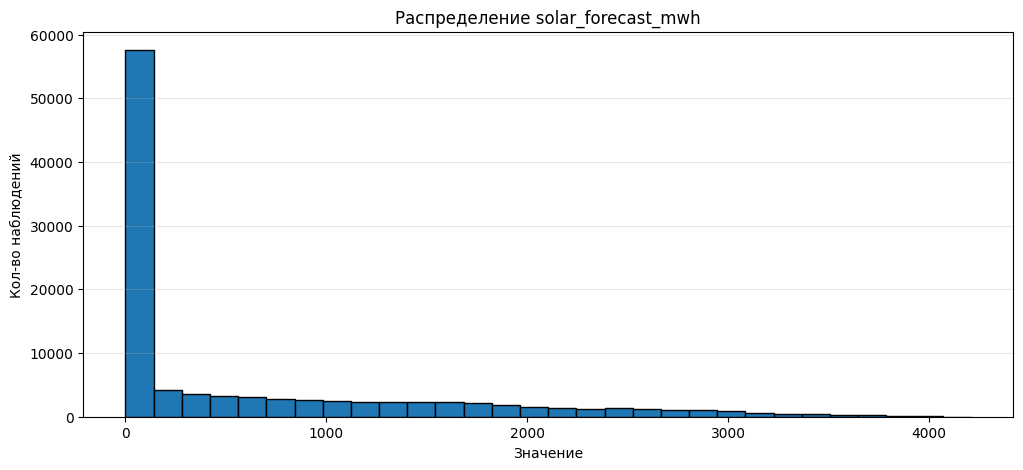

Признак nuclear_forecast_mwh


,Значение,"Доля, %"
0,1900.0,54.09
1,1428.0,14.20
2,1920.0,9.63
3,1440.0,7.53
4,1422.0,5.59


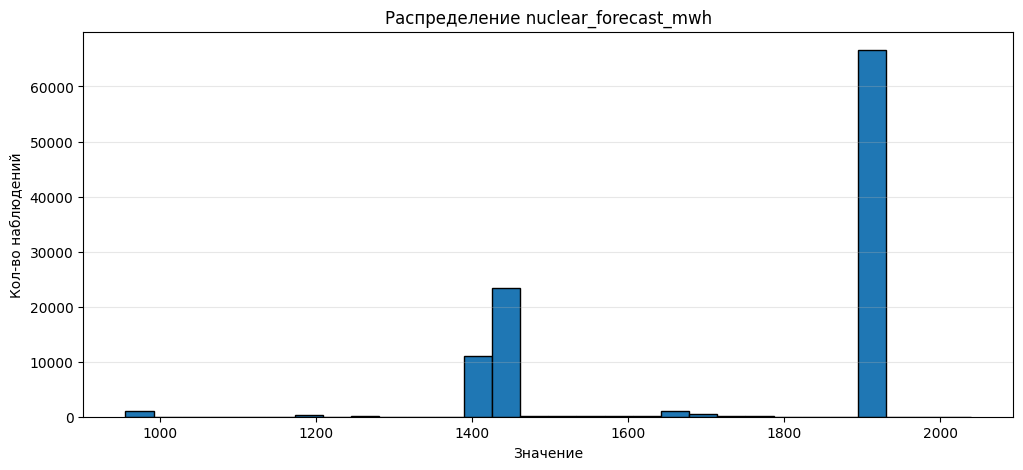

Признак temperature_forecast_c


,Значение,"Доля, %"
0,15.04,0.06
1,2.64,0.06
2,3.13,0.05
3,2.54,0.05
4,3.47,0.05


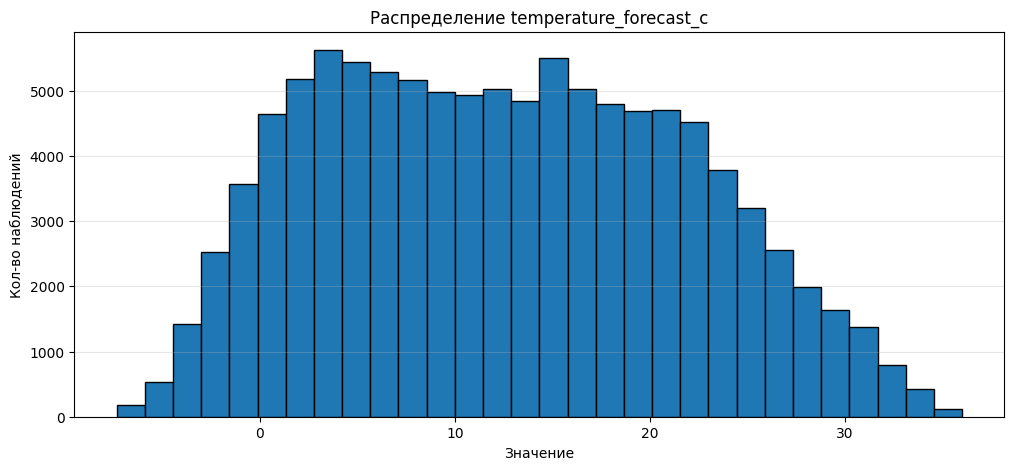

Признак net_exchange_forecast_mwh


,Значение,"Доля, %"
0,-600.0,3.05
1,-200.0,2.27
2,-1900.0,0.96
3,-1200.0,0.72
4,-2900.0,0.72


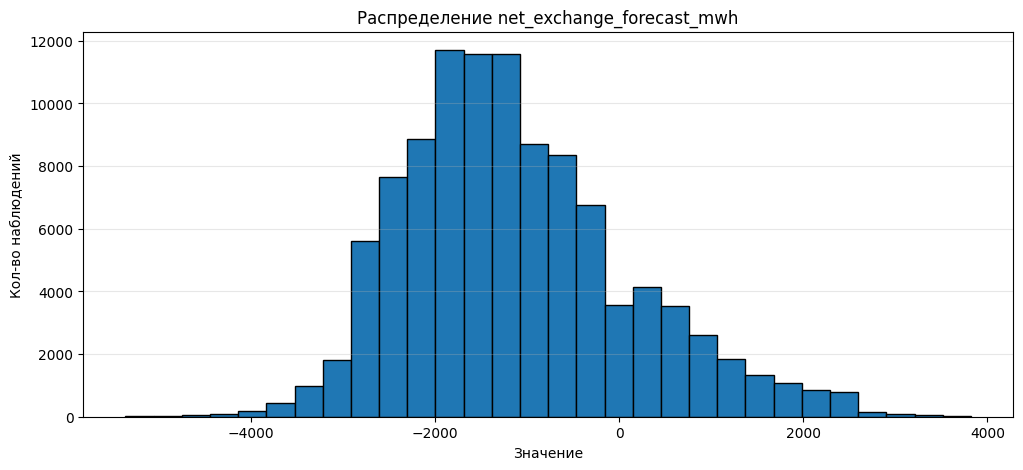

In [97]:
features=['demand_forecast_mwh','wind_forecast_mwh','solar_forecast_mwh','nuclear_forecast_mwh','temperature_forecast_c','net_exchange_forecast_mwh']
for feat in features:
   print(f'Признак {feat}')
   top5 = (df[feat].value_counts(normalize=True).head(5).mul(100).round(2).reset_index())
   top5.columns = ['Значение', 'Доля, %']
   display(top5)
   plt.figure(figsize=(12, 5))
   plt.hist(df[feat], bins=30, edgecolor='black')
   plt.title(f'Распределение {feat}')
   plt.xlabel('Значение')
   plt.ylabel('Кол-во наблюдений')
   plt.grid(axis='y', alpha=0.3)
   plt.show()

Для будущей модели бустинга признаки можно не преобразовывать, а для линейных моделей стоит еще предобработать некоторые

In [98]:
df_boosting=df.copy()
df_linear=df.copy()

df_linear=df_linear.drop(columns=[f'lag_{lag}' for lag in lags if lag < 96])

К wind_forecast_mwh стоит применить np.log1p, чтобы убрать перекос

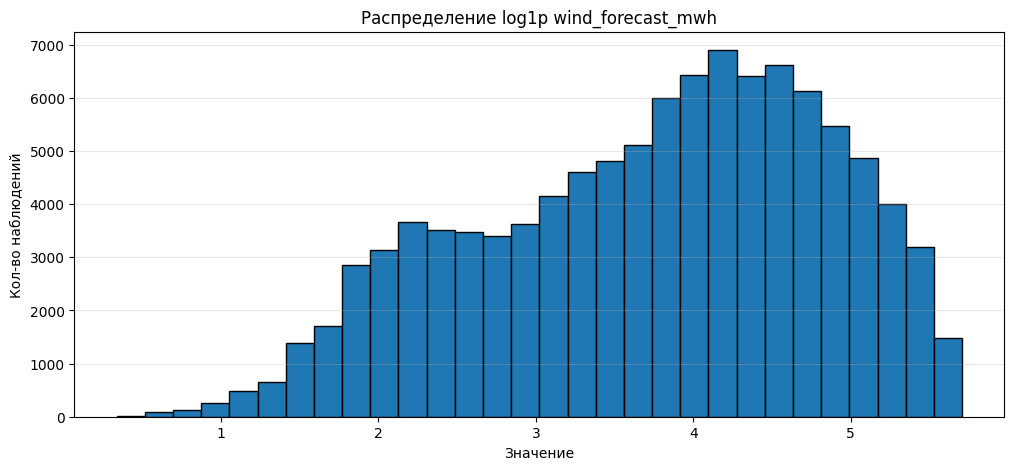

In [99]:
df_linear['wind_forecast_mwh']=np.log1p(df_linear['wind_forecast_mwh'])

plt.figure(figsize=(12, 5))
plt.hist(df_linear['wind_forecast_mwh'], bins=30, edgecolor='black')
plt.title(f'Распределение log1p wind_forecast_mwh')
plt.xlabel('Значение')
plt.ylabel('Кол-во наблюдений')
plt.grid(axis='y', alpha=0.3)
plt.show()

У признака nuclear_forecast_mwh распределение выглядит практически дискретным: 64% сэмплов это значения (1900,1920), 32.5% это значения (1422, 1424, 1428, 1440, 1442), и 3.5% остальные значения. Поэтому из этого признака можно сделать несколько категориальных. Повышенная выработка (1900 и 1920), среднее (менее 1900, но больше 1400) и остальное- пониженное

График таргета за день каждые 15 мин:

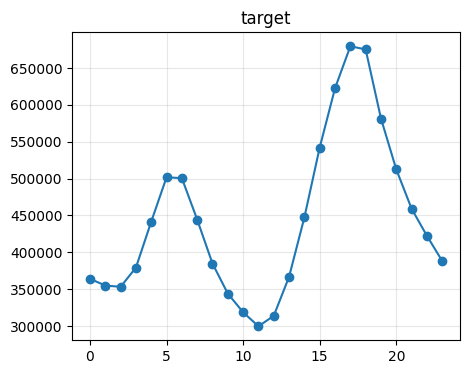

In [100]:
df["days"] = df['timestamp'].dt.hour

result = df.groupby('days')['target'].sum()
plt.figure(figsize=(5,4))
plt.plot(result.index, result.values, marker = "o")

plt.title('target')
plt.grid(alpha = 0.3)
plt.show()

Таргет по месяцам:

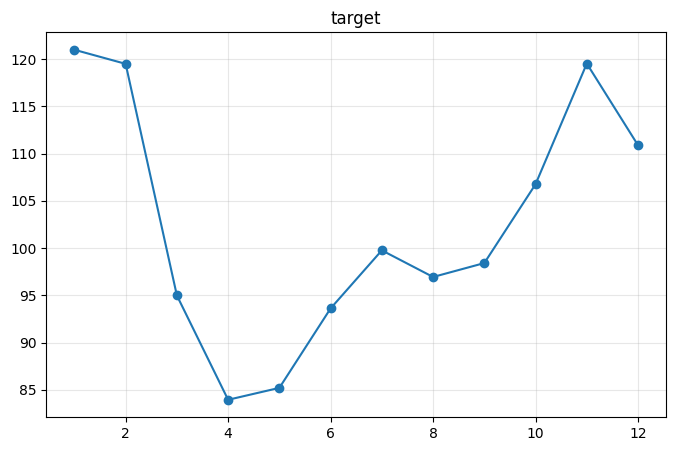

In [101]:
df["month"] = df["timestamp"].dt.month
df["month"]
result = df.groupby('month')["target"].mean()
plt.figure(figsize=(8,5))
plt.plot(result.index, result.values, marker = "o")

plt.title("target")
plt.grid(alpha = 0.3)
plt.show()

График таргета по дням недели в среднем:

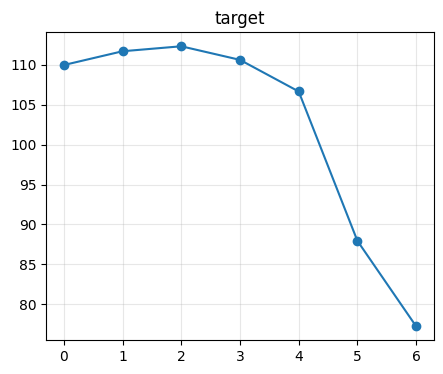

In [102]:
df["weekday"] = df["timestamp"].dt.day_of_week

result = df.groupby("weekday")['target'].mean()
plt.figure(figsize=(5, 4))
plt.plot(result.index, result.values, marker="o")
plt.title('target')
plt.grid(alpha=0.3) 
plt.show()


Расчет по временам года:

In [103]:
seasons = {12: "Зима", 1: "Зима", 2: "Зима",
           3: "Весна", 4: "Весна", 5: "Весна",
           6: "Лето", 7: "Лето", 8: "Лето",
           9: "Осень", 10: "Осень", 11: "Осень"}

df["season"] = df["timestamp"].dt.month.map(seasons)

# среднее, минимум и максимум одной таблицей
print(df.groupby("season")["target"].agg(["mean", "min", "max"]))

# количество отрицательных, положительных и нулевых цен
QH_min = df[df["target"] < 0]
QH_pos = df[df["target"] > 0]
QH_0 = df[df["target"] == 0]

print(QH_min.groupby("season")["target"].sum())
print(QH_pos.groupby("season")["target"].sum())
print(QH_0.groupby("season")["target"].count())

#прибыль + убыток за сезон
print(df.groupby("season")["target"].sum())

              mean     min      max
season                             
Весна    88.095266 -85.538  224.501
Зима    116.943958 -36.250  224.501
Лето     96.808798 -85.538  224.501
Осень   108.216302 -85.538  224.501
season
Весна   -44811.898
Зима     -1463.530
Лето    -32645.948
Осень   -11347.856
Name: target, dtype: float64
season
Весна    2378984.054
Зима     2965291.198
Лето     2597691.871
Осень    2847480.696
Name: target, dtype: float64
Series([], Name: target, dtype: int64)
season
Весна    2334172.156
Зима     2963827.668
Лето     2565045.923
Осень    2836132.840
Name: target, dtype: float64


Средняя цена ниже всего весной и выше всего зимой. Весной отрицательные цены встречаются чаще и бывают глубже, что, скорее всего, связано с избытком солнечной генерации при невысоком потреблении. Зимой отрицательных цен почти нет: солнечная генерация минимальна, а спрос выше

In [104]:
top10 = (df_linear['nuclear_forecast_mwh'].value_counts(normalize=True).head(10).mul(100).round(2).reset_index())
top10.columns = ['Значение', 'Доля, %']
display(top10)

,Значение,"Доля, %"
0,1900.0,54.09
1,1428.0,14.20
2,1920.0,9.63
3,1440.0,7.53
4,1422.0,5.59
5,1424.0,4.87
6,956.0,1.01
7,1442.0,0.53
8,1680.0,0.49
9,1660.0,0.46


In [105]:
df_linear['nuclear_high']=df_linear['nuclear_forecast_mwh'].isin([1900, 1920]).astype(int)
df_linear['nuclear_medium']=df_linear['nuclear_forecast_mwh'].between(1400, 1900, inclusive='neither').astype(int)
#nuclear_low не добавляем чтобы не создавать линейной зависимости
df_linear.drop(columns=['nuclear_forecast_mwh'],inplace=True)

Для получившихся признаков для датасета под линейные модели, кроме флагов перед обучением будем применять RobustScaler, чтобы у некоторых признаков убрать хвосты

Динамика таргета и признаков во времени по годам

In [106]:
def plot_time_patterns_years(df, feature):

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    days_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

    months_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

    palette = 'tab10'

    hourly = df.groupby(['year', df['hour']])[feature].median().reset_index()

    hourly.columns = ['year', 'hour', feature]

    sns.lineplot(data=hourly, x='hour', y=feature, hue='year', marker='o', ax=axes[0, 0], palette = palette)

    axes[0, 0].set_title('Динамика по часам')
    axes[0, 0].set_xlabel('Час')
    axes[0, 0].set_xticks(range(24))
    axes[0, 0].grid(True, alpha=0.5)

    daily = df.groupby(['year', df['day_of_week']])[feature].median().reset_index()

    daily.columns = ['year', 'day', feature]

    sns.lineplot(data=daily, x='day', y=feature, hue='year', marker='o', ax=axes[0, 1], palette = palette)

    axes[0, 1].set_title('Динамика по дням недели')
    axes[0, 1].set_xlabel('День недели')
    axes[0, 1].set_xticks(range(7))
    axes[0, 1].set_xticklabels(days_labels)
    axes[0, 1].grid(True, alpha=0.5)

    weekly = df.groupby(['year', df['week_of_year']])[feature].median().reset_index()

    weekly.columns = ['year', 'week', feature]

    sns.lineplot(data=weekly, x='week', y=feature, hue='year', ax=axes[1, 0], palette = palette)

    axes[1, 0].set_title('Динамика по неделям года')
    axes[1, 0].set_xlabel('Неделя года')
    axes[1, 0].grid(True, alpha=0.5)

    monthly = df.groupby(['year', df['month']])[feature].median().reset_index()

    monthly.columns = ['year', 'month', feature]

    sns.lineplot(data=monthly, x='month', y=feature, hue='year', marker='o', ax=axes[1, 1], palette = palette)

    axes[1, 1].set_title('Динамика по месяцам')
    axes[1, 1].set_xticks(range(1, 13))
    axes[1, 1].set_xticklabels(months_labels)
    axes[1, 1].grid(True, alpha=0.5)

    fig.suptitle(f'Временные паттерны: {feature}', fontsize=15)

    plt.tight_layout()
    plt.show()

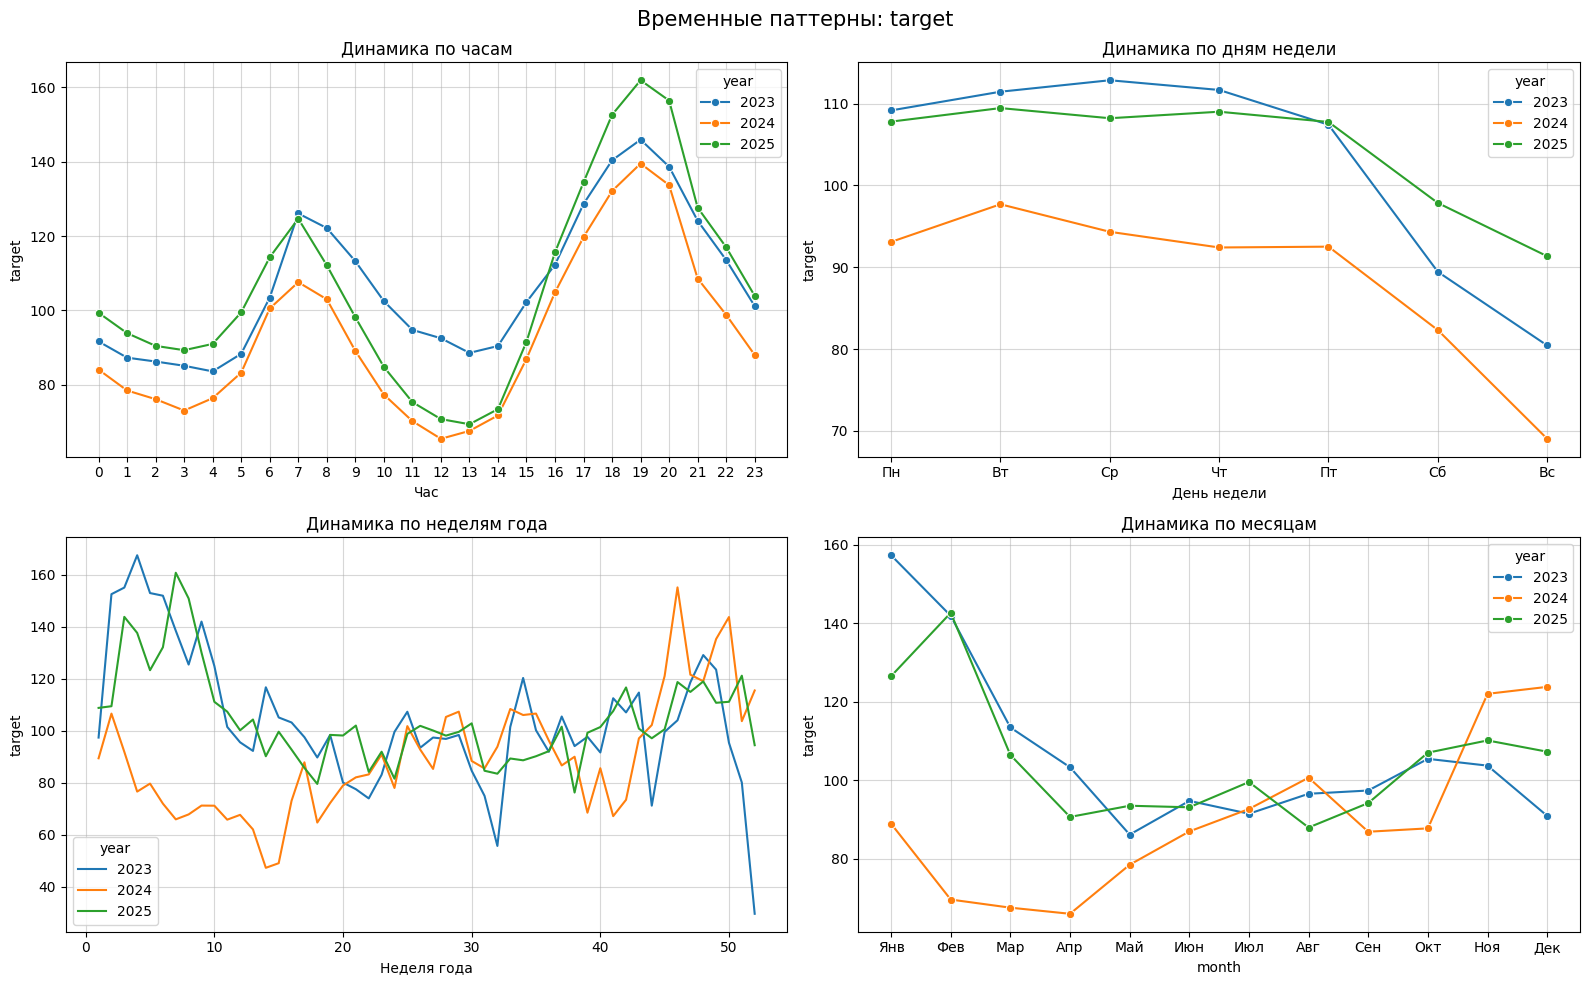

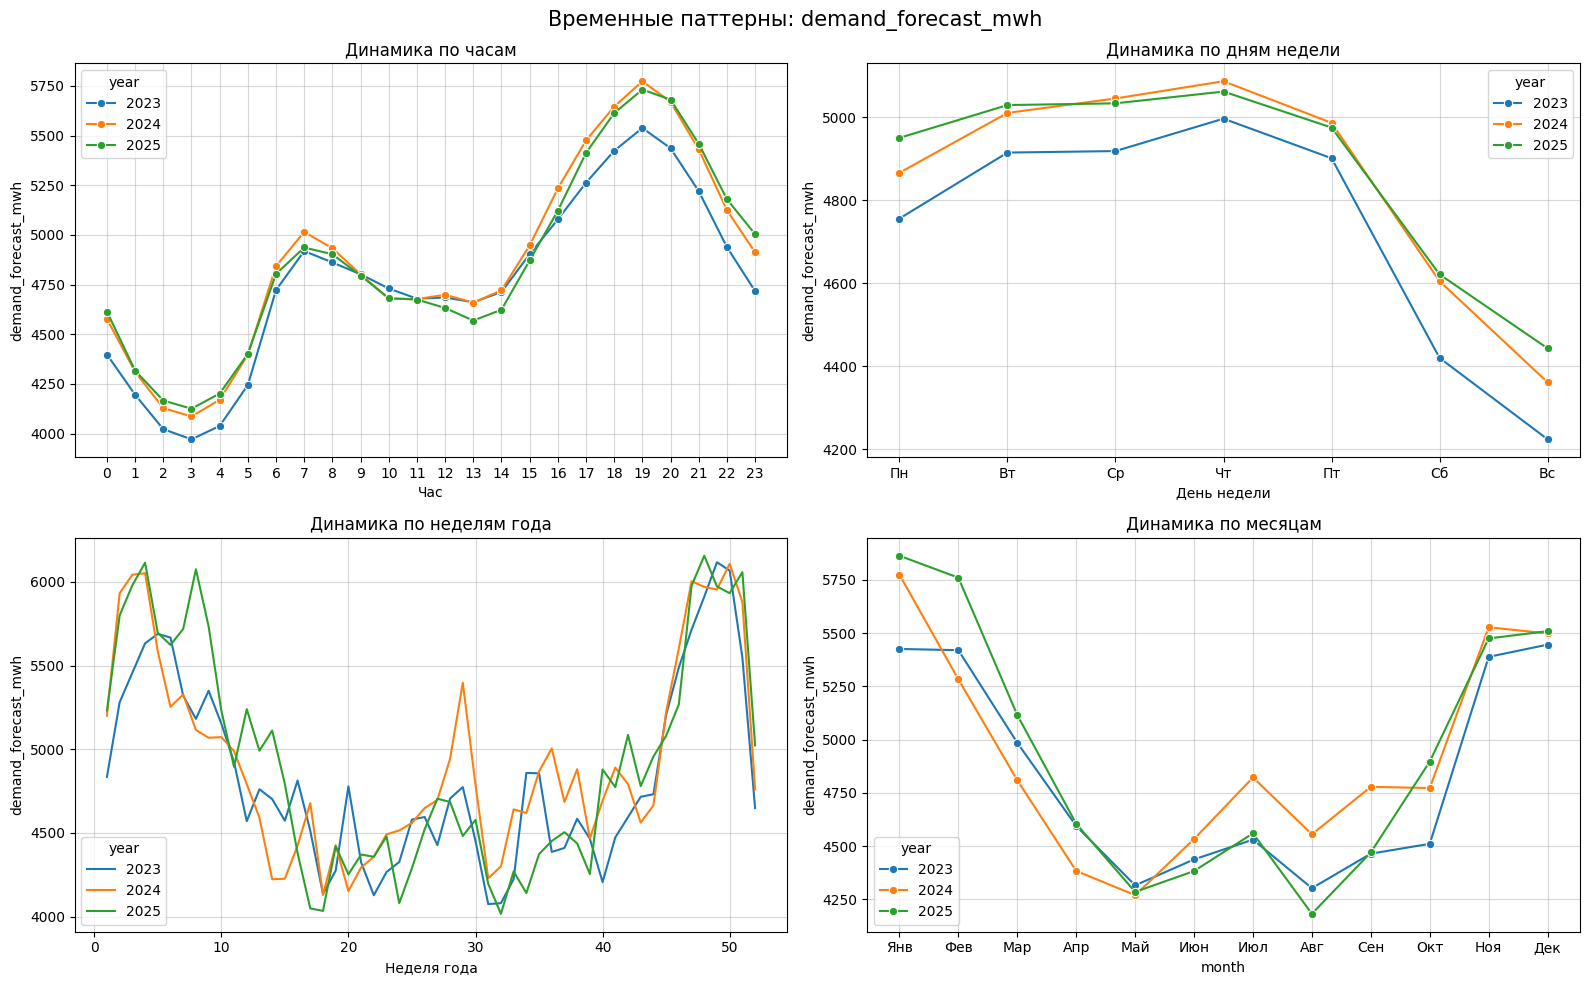

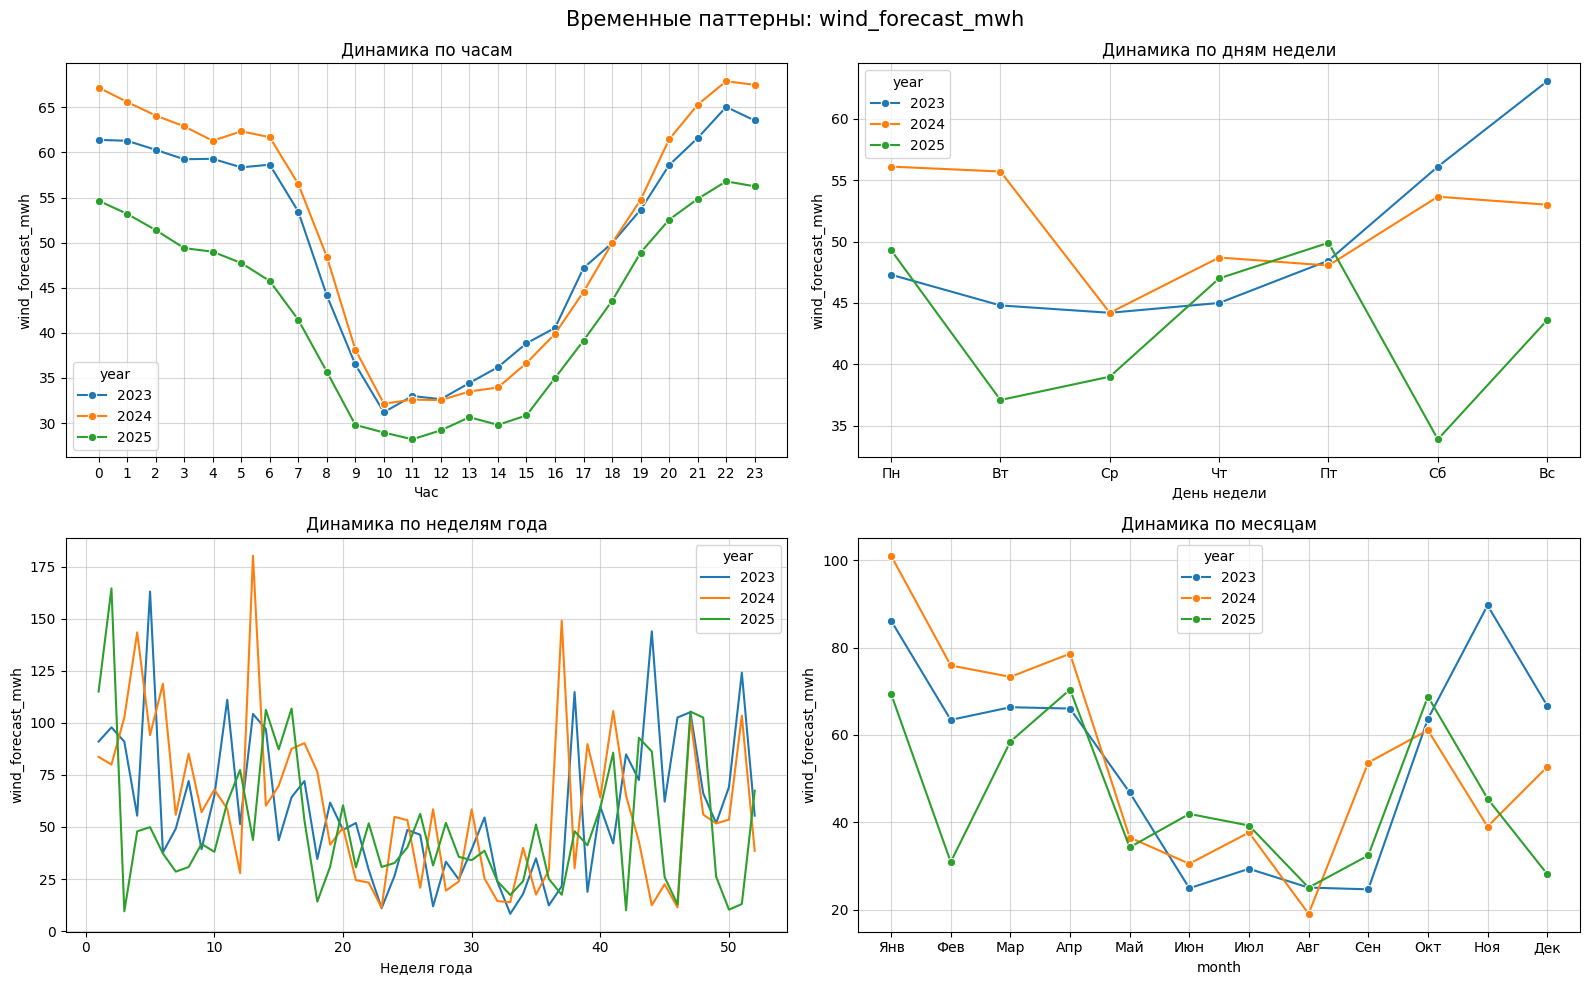

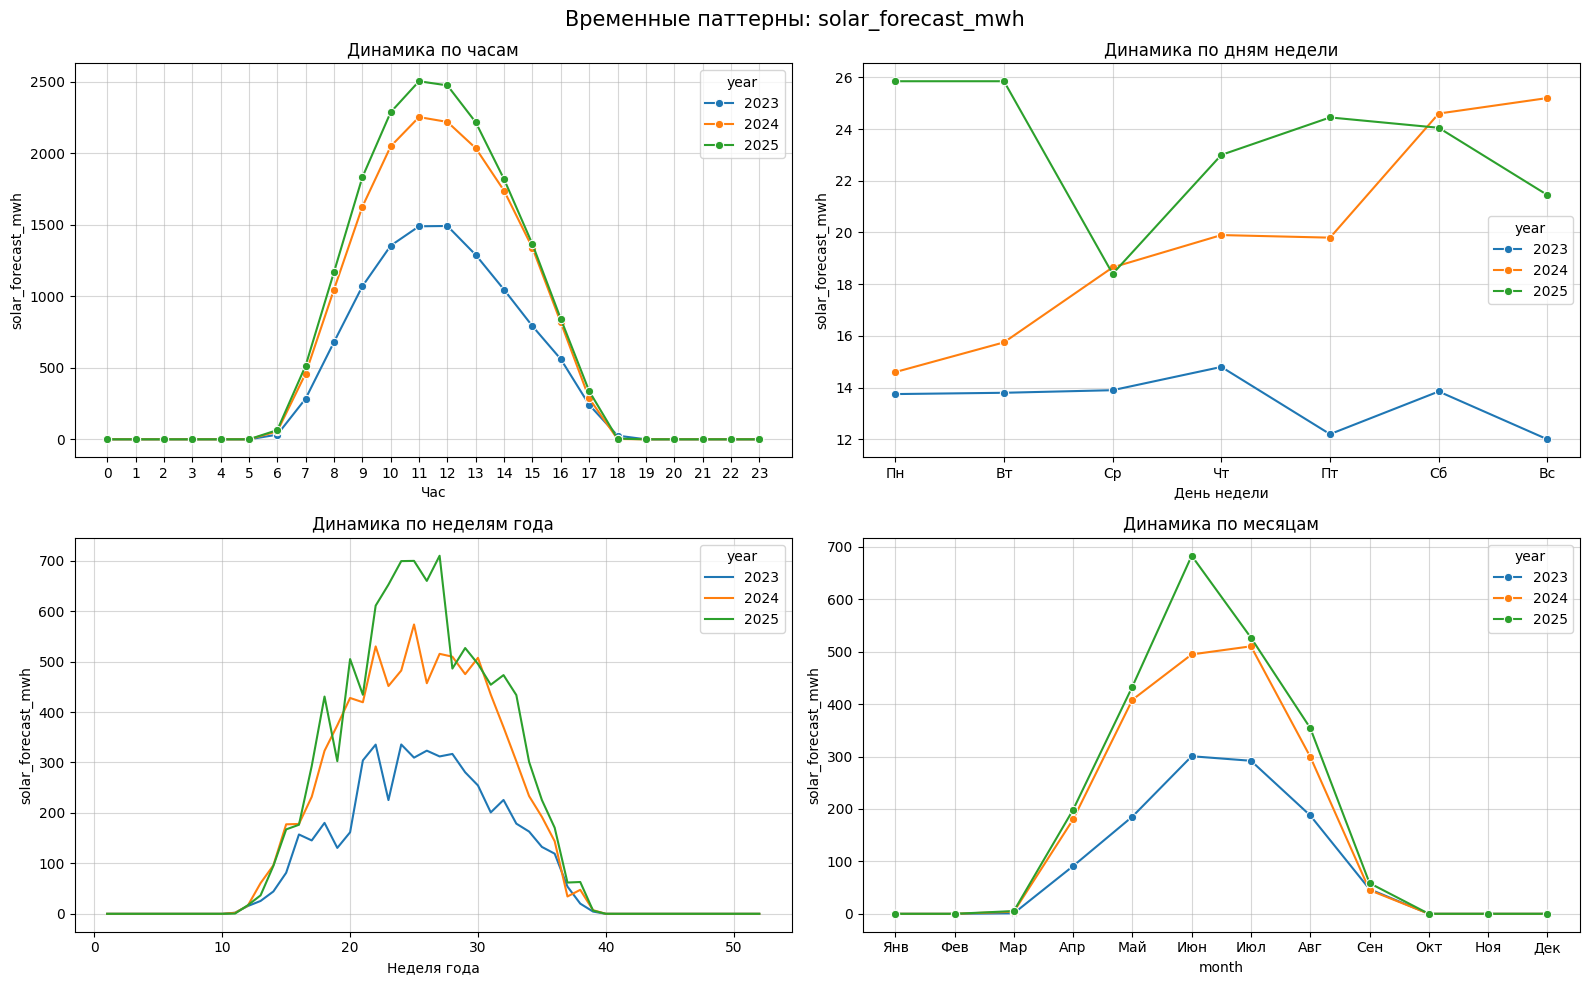

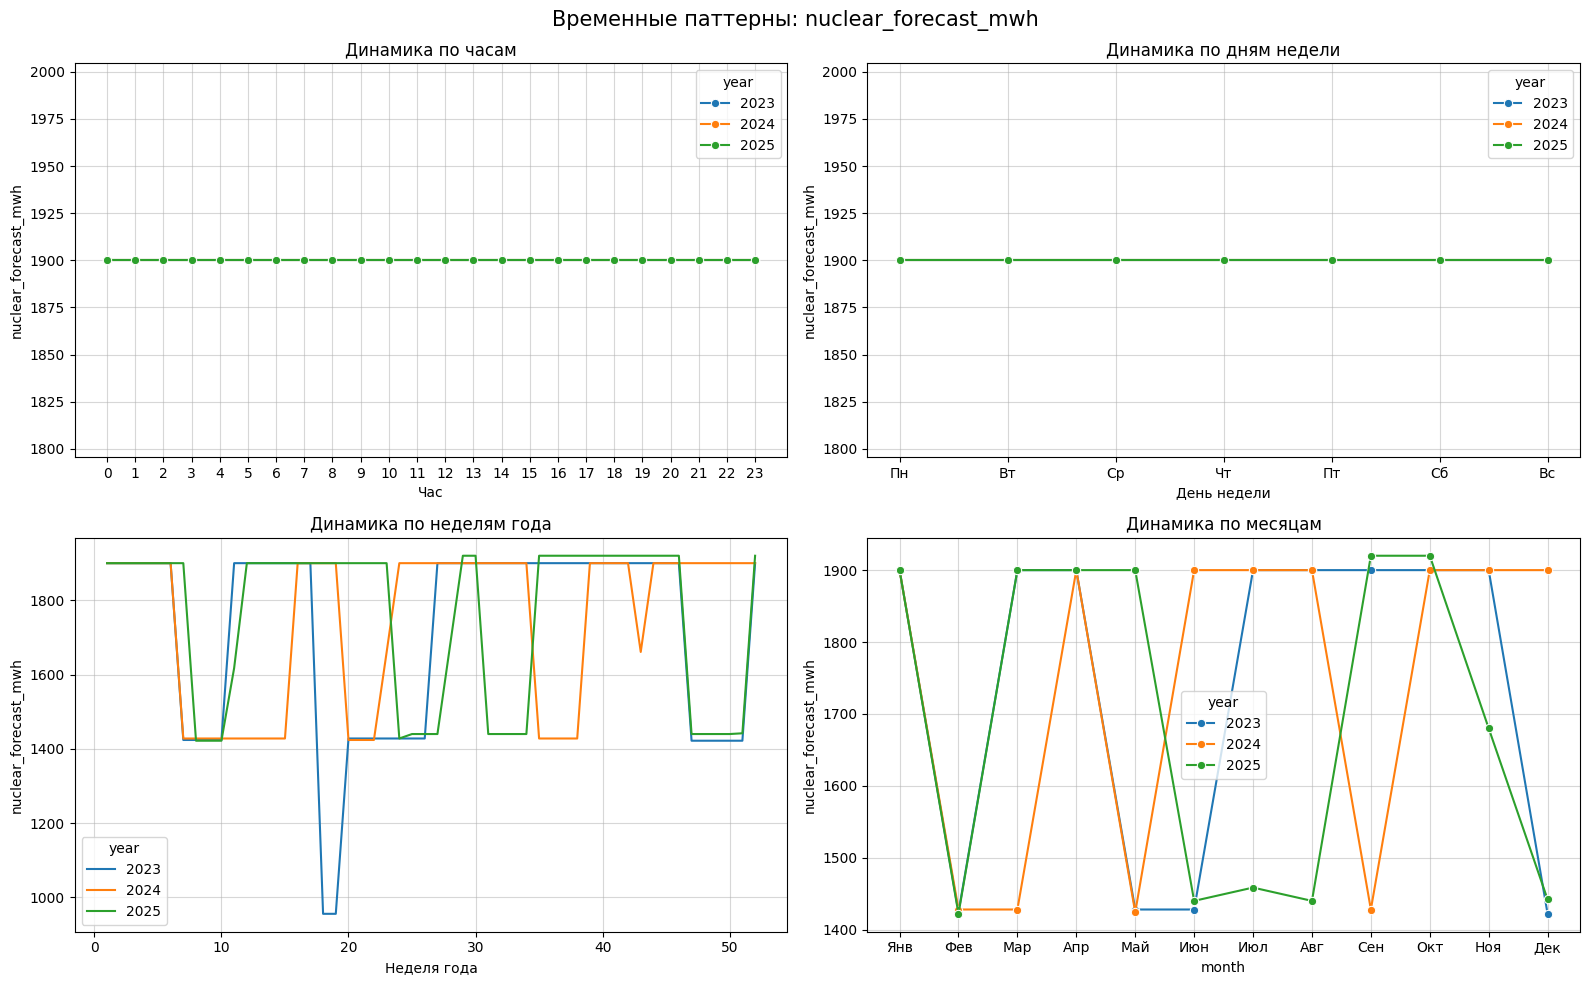

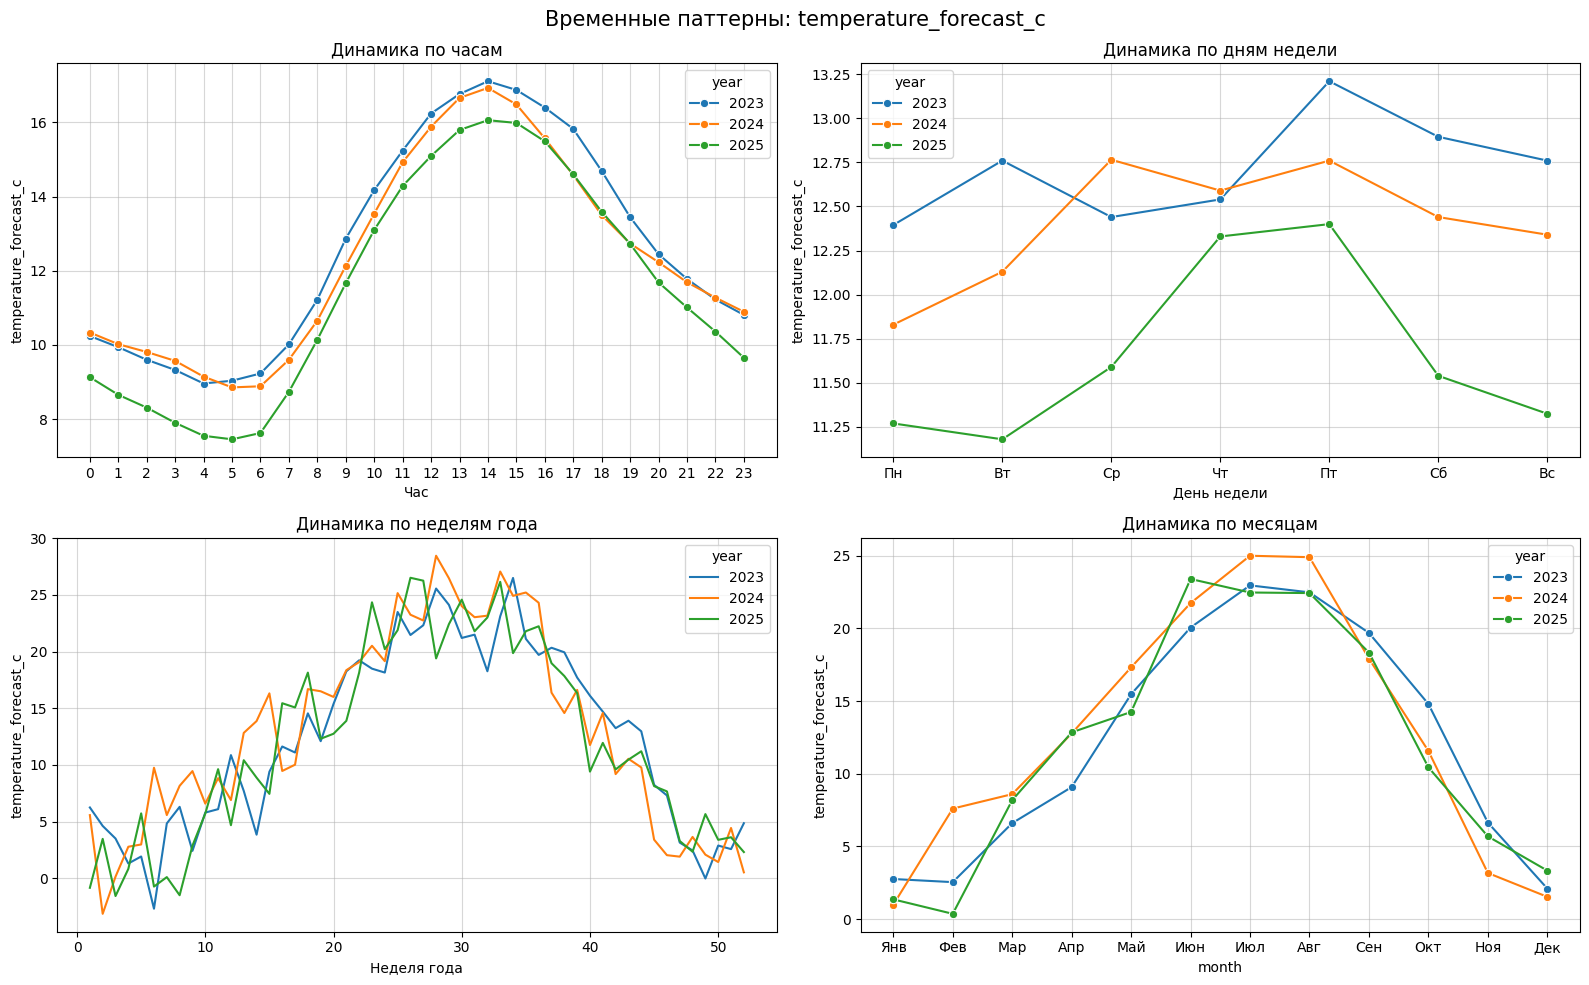

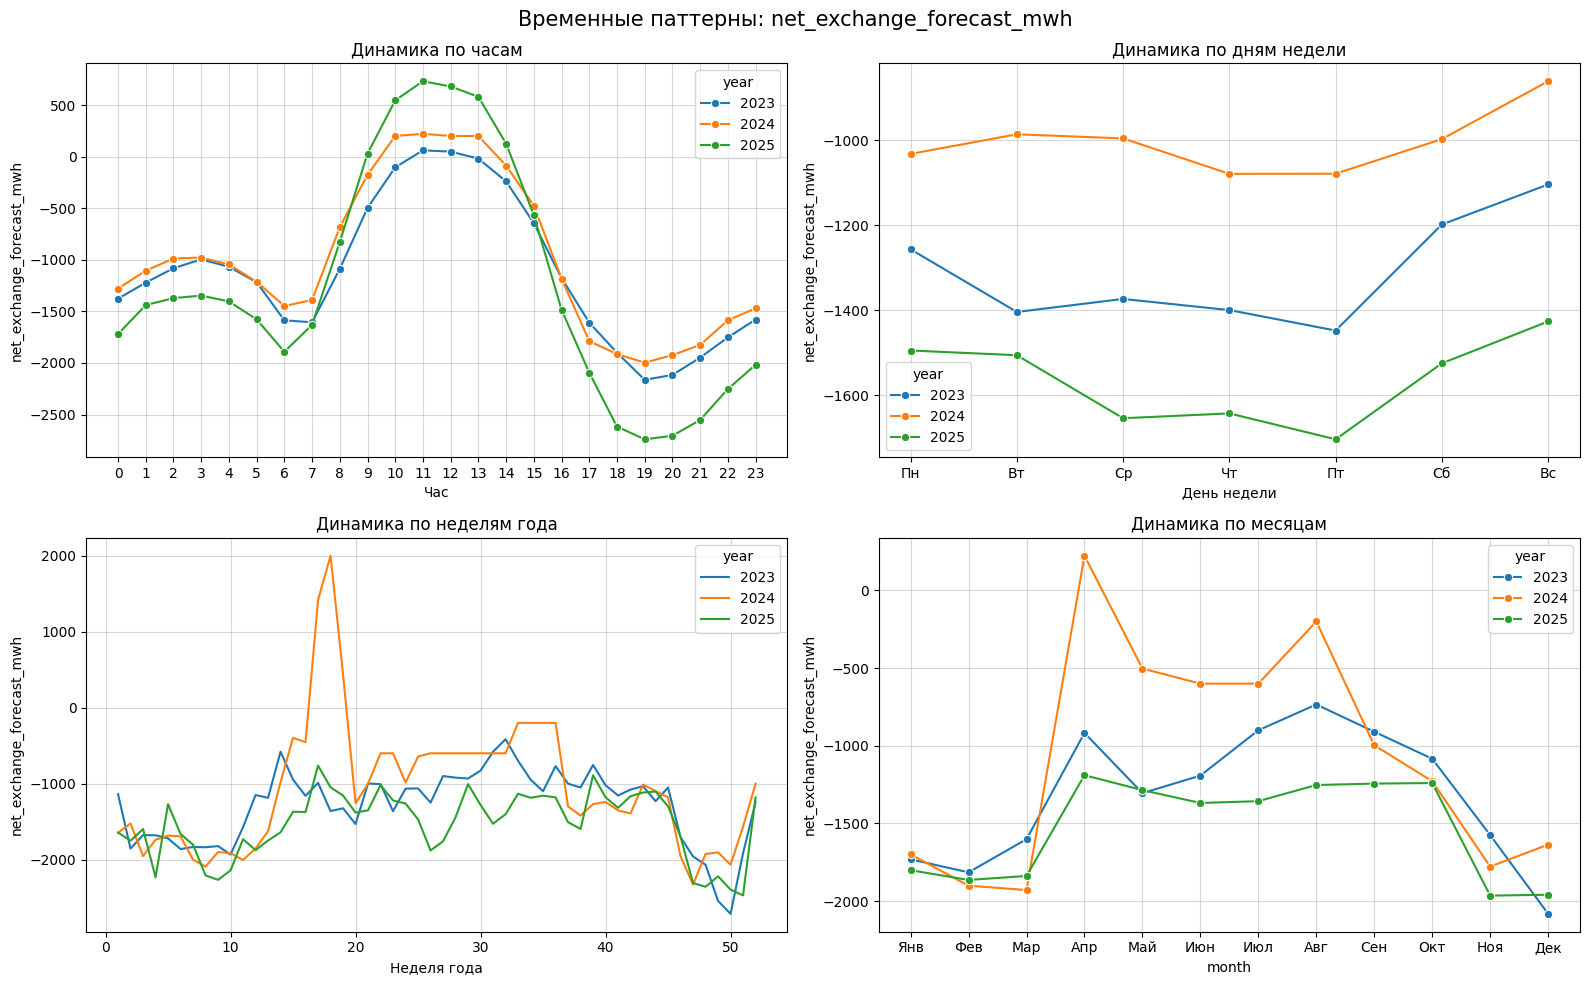

In [107]:
features = ['target','demand_forecast_mwh', 'wind_forecast_mwh',
       'solar_forecast_mwh', 'nuclear_forecast_mwh', 'temperature_forecast_c',
       'net_exchange_forecast_mwh',]

for feature in features:
    plot_time_patterns_years(df, feature)

Проверим мультиколлинеарность признаков

По результатам vif, стоит убрать hour, nuclear_high, rolling_mean_48, rolling_mean_96, rolling_mean_192, lag_101, lag_102, lag_103 lag_189, lag_190, lag_191, lag_193, lag_194, lag_195, lag_196, lag_284, lag_289, lag_290, lag_291 из датасета под линейные модели

In [110]:
cols=['hour', 'nuclear_high', 'rolling_mean_48', 'rolling_mean_96', 'rolling_mean_192', 'lag_101', 'lag_102',
      'lag_103', 'lag_189', 'lag_190', 'lag_191', 'lag_193', 'lag_194', 'lag_195', 'lag_196', 'lag_284', 'lag_289', 'lag_290', 'lag_291', 'year', 'week_of_year']
df_linear.drop(columns=cols,inplace=True)

In [111]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X=df_linear.drop(columns=['target', 'timestamp'])
X=sm.add_constant(X)
vif=pd.DataFrame({'feature':X.columns,'VIF':[variance_inflation_factor(X.values,i) for i in range(X.shape[1])]})
vif=vif[vif['feature']!='const'].sort_values('VIF', ascending=False)
print(vif)

                      feature        VIF
10                    lag_100  10.060772
36                    lag_292   9.828015
29                    lag_281   9.685020
30                    lag_282   9.612247
35                    lag_288   9.553537
34                    lag_287   9.392855
33                    lag_286   9.381386
19                    lag_188   9.345640
31                    lag_283   8.793407
23                    lag_199   8.497741
22                    lag_198   8.480865
32                    lag_285   8.471871
39                    lag_295   8.417905
6                      lag_96   8.347144
38                    lag_294   8.325673
37                    lag_293   8.270363
17                    lag_186   8.072524
20                    lag_192   8.070235
16                    lag_185   8.060064
40                    lag_296   8.012132
9                      lag_99   7.947208
18                    lag_187   7.942323
11                    lag_104   7.897601
42            ro

In [112]:
df_linear.columns

Index(['timestamp', 'demand_forecast_mwh', 'wind_forecast_mwh',
       'solar_forecast_mwh', 'temperature_forecast_c',
       'net_exchange_forecast_mwh', 'target', 'lag_96', 'lag_97', 'lag_98',
       'lag_99', 'lag_100', 'lag_104', 'lag_124', 'lag_144', 'lag_164',
       'lag_184', 'lag_185', 'lag_186', 'lag_187', 'lag_188', 'lag_192',
       'lag_197', 'lag_198', 'lag_199', 'lag_200', 'lag_220', 'lag_240',
       'lag_260', 'lag_280', 'lag_281', 'lag_282', 'lag_283', 'lag_285',
       'lag_286', 'lag_287', 'lag_288', 'lag_292', 'lag_293', 'lag_294',
       'lag_295', 'lag_296', 'lag_672', 'rolling_mean_24', 'month',
       'day_of_week', 'day_of_month', 'quarter_hour', 'is_weekend_holiday',
       'nuclear_medium'],
      dtype='object')

### Корреляции

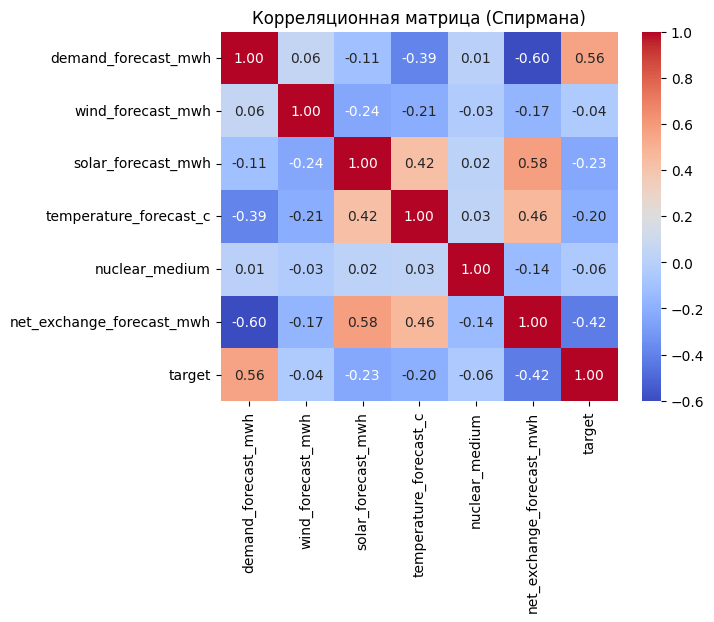

In [113]:
df_init = df_linear[['demand_forecast_mwh', 'wind_forecast_mwh',
       'solar_forecast_mwh', 'temperature_forecast_c','nuclear_medium',
       'net_exchange_forecast_mwh', 'target']]

corr = df_init.corr(method='spearman', numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Корреляционная матрица (Спирмана)")
plt.show()

| Признаки | Корреляция | Комментарий |
|---|---|---|
| demand и net_exchange | −0.60 | Чем больше потребление тем больше импортируют (отрицательная связь) |
| solar_forecast и net_exchange | 0.58 | Чем больше выроботка солнцем, тем меньше импортируют (положительная связь) |
| nuclear и др | ~0 | АЭС не зависит от других признаков |


>С целевеой переменной лучше всего коллерируют demand_forecast_mwh (положительная связь) и net_exchange_forecast_mwh(отрицательная связь)

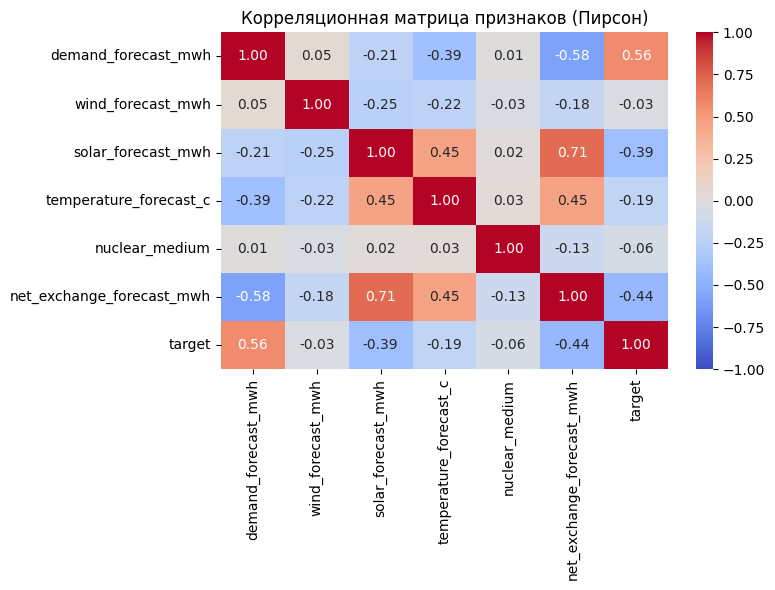

In [114]:
corr = df_init.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Корреляционная матрица признаков (Пирсон)")
plt.tight_layout()
plt.show()

# Вывод
В данных отсутсвуют дубликаты, временной ряд непрерывный (нет пропусков в наблюдениях), также отсутсвуют резкие изменения формы ряда или другие структурные изменения.

Пропуски присутсвуют только в таргете, заполнены медианной по окну соответсвующих предыдущих наблюдений. В таргете присутсвуют выбросы, было принято решение обрезать их по квантилям: снизу 5% отрицательных значений и сверху 95% положительных значений.

Построена коррелограмма (acf) таргета со своими лагами и выявлены несколько сезонностей: недельная, суточная, 12-часовая, 6-часовая. На ее основе составлены лаговые признаки и скользящие средние по таргету.

Были добавлены календарные признаки, основываясь на времени Будапешта: месяц, день месяца, день недели, номер 15-минутки внутри суток, а также флаг выходных и гос. праздников Венгрии.

В дополнительных признаках (данных изначально) распределение стремится к нормальному (где-то с хвостами), кроме wind_forecast_mwh, nuclear_forecast_mwh и solar_forecast_mwh. К wind_forecast_mwh применен безопасный логарифм. nuclear_forecast_mwh преобразован в категориальный и сделан one-hot encoding.


При построении корреляционной матрицы Спирмана было обнаружено:
* С целевой переменной лучше всего коллерируют demand(положительная связь) net_exchange(отрицательная связь)
Также присутвует связи: 
* demand и net_exchange (чем больше потребление тем больше импортируют (отрицательная связь)), 
* solar_forecast и net_exchange (чем больше выроботка солнцем, тем меньше импортируют (положительная связь))
* А вот у nuclear почти 0 корреляция с таргетом и остальными признаками.

На основе получившегося датасета был выбран датасет под будующие линейные модели. С признаками без пропусков и дальнейшим отбором с помощью анализа их мультиколлинеарности. Были отобраны признаки с vif<10.1

